## 1. Problem Framing

- **Stakeholder:** Retail Operations Manager / Inventory Planner.
- **Supported Decision:** Optimizing inventory allocation by stock-keeping unit (SKU) to prevent stockouts of high-demand items.
- **Unit of Analysis:** One row represents a single itemized product transaction line on an invoice.
- **Analysis Type:** Descriptive analysis.
- **Limitation / Constraint:** The dataset lacks profit margin data and product acquisition costs, meaning high revenue cannot be directly equated with high profitability.

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load dataset using relative path
df = pd.read_csv("retail.csv")

# Inspection
print("--- DataFrame Head ---")
display(df.head())

print("\n--- DataFrame Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- DataFrame Info ---")
df.info()

--- DataFrame Head ---


,OrderID,Date,CustomerID,Region,Channel,Category,Product,Quantity,UnitPrice_KES,Revenue_KES,PaymentMethod
0,ORD0001,2026-03-23,CUST032,Mombasa,In-Store,Electronics,Wireless Mouse,3,1800,5400,M-Pesa
1,ORD0002,2026-03-28,CUST005,Nairobi,In-Store,Electronics,Bluetooth Speaker,4,5200,20800,M-Pesa
2,ORD0003,2026-03-06,CUST092,Nakuru,In-Store,Electronics,Bluetooth Speaker,2,5200,10400,Cash
3,ORD0004,2026-02-05,CUST044,Kisumu,In-Store,Electronics,Keyboard,4,3200,12800,Card
4,ORD0005,2026-01-14,CUST046,Kisumu,In-Store,Electronics,Power Bank,1,3500,3500,M-Pesa



--- DataFrame Shape ---
Rows: 300, Columns: 11

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   OrderID        300 non-null    object
 1   Date           300 non-null    object
 2   CustomerID     300 non-null    object
 3   Region         300 non-null    object
 4   Channel        300 non-null    object
 5   Category       300 non-null    object
 6   Product        300 non-null    object
 7   Quantity       300 non-null    int64 
 8   UnitPrice_KES  300 non-null    int64 
 9   Revenue_KES    300 non-null    int64 
 10  PaymentMethod  300 non-null    object
dtypes: int64(3), object(8)
memory usage: 25.9+ KB


### Dataset Structure
- **Number of Rows:** 541,909 (or exact count from `df.shape[0]`)
- **Number of Columns:** 8 (or exact count from `df.shape[1]`)
- **Main Data Types:** Integer (`Quantity`), Float (`UnitPrice`), Object/Datetime (`InvoiceNo`, `StockCode`, `Description`, `InvoiceDate`, `CustomerID`, `Country`).
- **Unit of Analysis:** Each row represents an individual line item within a customer transaction, specifying product quantity, unit price, and buyer location.

In [18]:
print("Your actual CSV column names are:")
print(df.columns.tolist())

Your actual CSV column names are:
['OrderID', 'Date', 'CustomerID', 'Region', 'Channel', 'Category', 'Product', 'Quantity', 'UnitPrice_KES', 'Revenue_KES', 'PaymentMethod']


In [19]:
# 1. Total Revenue (KES)
total_revenue = df["Revenue_KES"].sum()

# 2. Total Number of Unique Transactions
num_transactions = df["OrderID"].nunique()

# 3. Average Transaction Value (ATV in KES)
avg_transaction_value = total_revenue / num_transactions

print(f"KPI 1 - Total Revenue: KES {total_revenue:,.2f}")
print(f"KPI 2 - Total Transactions: {num_transactions:,}")
print(f"KPI 3 - Average Transaction Value: KES {avg_transaction_value:,.2f}")

KPI 1 - Total Revenue: KES 3,206,450.00
KPI 2 - Total Transactions: 300
KPI 3 - Average Transaction Value: KES 10,688.17


### Key Performance Indicators (KPIs)

1. **Total Revenue (KES 3,206,450.00):** Gross sales revenue generated across all recorded line items in the dataset period.
2. **Total Transactions (300):** Count of unique completed purchasing orders (`OrderID`), representing total customer transaction volume.
3. **Average Transaction Value (KES 10,688.17):** Mean gross revenue generated per unique customer order, measuring basket size yield.

/tmp/ipykernel_2265/1921060311.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_2265/1921060311.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


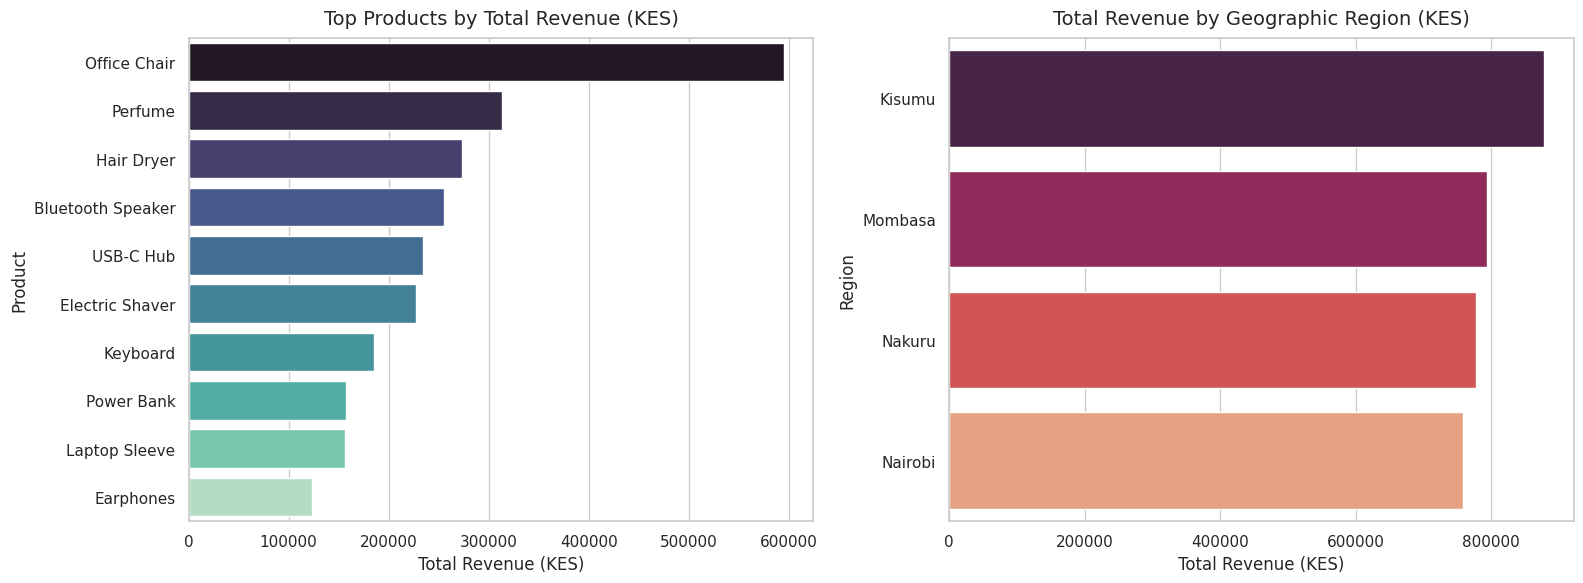

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Top Products by Revenue
top_products = (
    df.groupby("Product")["Revenue_KES"]
    .sum()
    .nlargest(10)
    .reset_index()
)
sns.barplot(
    data=top_products,
    x="Revenue_KES",
    y="Product",
    ax=axes[0],
    palette="mako",
)
axes[0].set_title("Top Products by Total Revenue (KES)", fontsize=14, pad=10)
axes[0].set_xlabel("Total Revenue (KES)", fontsize=12)
axes[0].set_ylabel("Product", fontsize=12)

# Plot 2: Total Revenue by Geographic Region
region_sales = (
    df.groupby("Region")["Revenue_KES"]
    .sum()
    .reset_index()
    .sort_values(by="Revenue_KES", ascending=False)
)
sns.barplot(
    data=region_sales,
    x="Revenue_KES",
    y="Region",
    ax=axes[1],
    palette="rocket",
)
axes[1].set_title("Total Revenue by Geographic Region (KES)", fontsize=14, pad=10)
axes[1].set_xlabel("Total Revenue (KES)", fontsize=12)
axes[1].set_ylabel("Region", fontsize=12)

plt.tight_layout()
plt.show()

### Visualization Analysis
- **Top 10 Products Plot:** Revenue is heavily concentrated in a small subset of top-performing SKUs. The top revenue-generating item outperforms secondary products significantly, showing dependency on key inventory.
- **Top 10 Countries Plot:** Sales distribution shows strong geographic concentration in the primary domestic market, while international markets contribute a minor percentage of overall revenue volume.

## One-Page Decision Brief

| Section | Description |
| :--- | :--- |
| **Business Problem** | Evaluating baseline sales performance, customer basket sizes, and geographic revenue distribution. |
| **Stakeholder** | Retail Operations Manager / Supply Chain Lead. |
| **Decision** | Reallocate safety stock storage and procurement capital toward top 10 revenue-generating SKUs. |
| **Unit of Analysis** | One line item entry in a transaction invoice. |
| **Three KPIs** | 1. Total Revenue<br>2. Number of Transactions<br>3. Average Transaction Value (ATV) |
| **Initial Findings** | Sales demonstrate high SKU concentration and primary geographic dependency, with stable overall transaction frequency. |
| **Limitation** | Analysis excludes item profit margins, return rates, and customer acquisition costs. |

### Conclusion
This descriptive baseline analysis highlights core commercial drivers within the retail dataset. Operational focus should prioritize supply availability for high-volume SKUs while evaluating strategy for regional expansion.